# M10–M12: Sentence Embedding, HDBSCAN và Outlier Analysis

Notebook này trình bày các artifact và kết quả đã tạo bởi pipeline M10–M12.
Các ô bên dưới chỉ đọc file để kiểm tra và trực quan hóa; không tạo lại
embedding, không chạy lại HDBSCAN và không thay đổi nhãn thủ công.

- M10: so sánh MiniLM/MPNet và hai kiểu đầu vào.
- M11: xem số cụm, tỷ lệ nhiễu và hình phân cụm.
- M12: xem tỷ lệ outlier và các ví dụ đã được nhận xét.

In [30]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

assert (ROOT / "configs/embeddings.yaml").exists(), (
    "Hãy chạy notebook từ thư mục gốc đồ án hoặc notebooks/"
)

M11_DIR = ROOT / "results/hdbscan"
M12_DIR = M11_DIR / "outlier_analysis"
FIGURES_DIR = M11_DIR / "figures"

pd.set_option("display.max_colwidth", 120)
print("Thư mục đồ án:", ROOT)

Thư mục đồ án: C:\Users\khanh\OneDrive\Documents\NLP\đồ án NLP\vietnamese-news-topic-discovery


## 1. Embedding M10

Bốn artifact dưới đây dùng cùng 6.493 `article_id` theo cùng thứ tự.
Hai mô hình là MiniLM và MPNet; mỗi mô hình có `title_only` và
`title_content` (tiêu đề cộng 60 từ đầu nội dung).

In [31]:
artifacts = {
    "minilm_title_content": "m10_v1_train_minilm.npz",
    "mpnet_title_content": "m10_v1_train_mpnet.npz",
    "minilm_title_only": "m10_v1_train_title_only_minilm.npz",
    "mpnet_title_only": "m10_v1_train_title_only_mpnet.npz",
}

embedding_rows = []
id_orders = []

for run, filename in artifacts.items():
    path = ROOT / "artifacts/embeddings" / filename
    with np.load(path, allow_pickle=False) as saved:
        ids = saved["article_ids"].tolist()
        vectors = saved["vectors"]

        embedding_rows.append({
            "embedding_run": run,
            "n_articles": len(ids),
            "dimensions": vectors.shape[1],
            "finite_vectors": bool(np.isfinite(vectors).all()),
            "unique_ids": len(set(ids)) == len(ids),
        })
        id_orders.append(ids)

display(pd.DataFrame(embedding_rows))
print("Bốn artifact cùng thứ tự article_id:",
      all(ids == id_orders[0] for ids in id_orders))

,embedding_run,n_articles,dimensions,finite_vectors,unique_ids
0,minilm_title_content,6493,384,True,True
1,mpnet_title_content,6493,768,True,True
2,minilm_title_only,6493,384,True,True
3,mpnet_title_only,6493,768,True,True


Bốn artifact cùng thứ tự article_id: True


## 2. Kết quả HDBSCAN M11

Bảng summary có 32 run: 4 embedding × 8 cấu hình HDBSCAN.
Bảng dưới tập trung vào `eom_15_5` và `leaf_15_5` để so sánh
số cụm, bài nhiễu và kích thước cụm lớn nhất.

In [32]:
summary = pd.read_csv(
    M11_DIR / "m11_summary.csv",
    encoding="utf-8-sig",
)

selected = summary[
    summary["experiment"].isin(["eom_15_5", "leaf_15_5"])
][
    [
        "embedding_run",
        "experiment",
        "n_articles",
        "n_clusters",
        "n_noise",
        "noise_percent",
        "largest_cluster",
    ]
].sort_values(["embedding_run", "experiment"])

print("Số run trong summary:", len(summary))
display(selected)

Số run trong summary: 32


,embedding_run,experiment,n_articles,n_clusters,n_noise,noise_percent,largest_cluster
1,minilm_title_content,eom_15_5,6493,101,1608,24.77,854
6,minilm_title_content,leaf_15_5,6493,126,2310,35.58,116
9,minilm_title_only,eom_15_5,6493,100,1956,30.12,492
14,minilm_title_only,leaf_15_5,6493,116,2540,39.12,132
17,mpnet_title_content,eom_15_5,6493,110,1660,25.57,227
22,mpnet_title_content,leaf_15_5,6493,124,2148,33.08,104
25,mpnet_title_only,eom_15_5,6493,106,2082,32.07,329
30,mpnet_title_only,leaf_15_5,6493,120,2602,40.07,93


### 2.1. So sánh 32 run

Hai hình sau so sánh số cụm và tỷ lệ bài nhiễu của bốn embedding
trên tám cấu hình HDBSCAN.

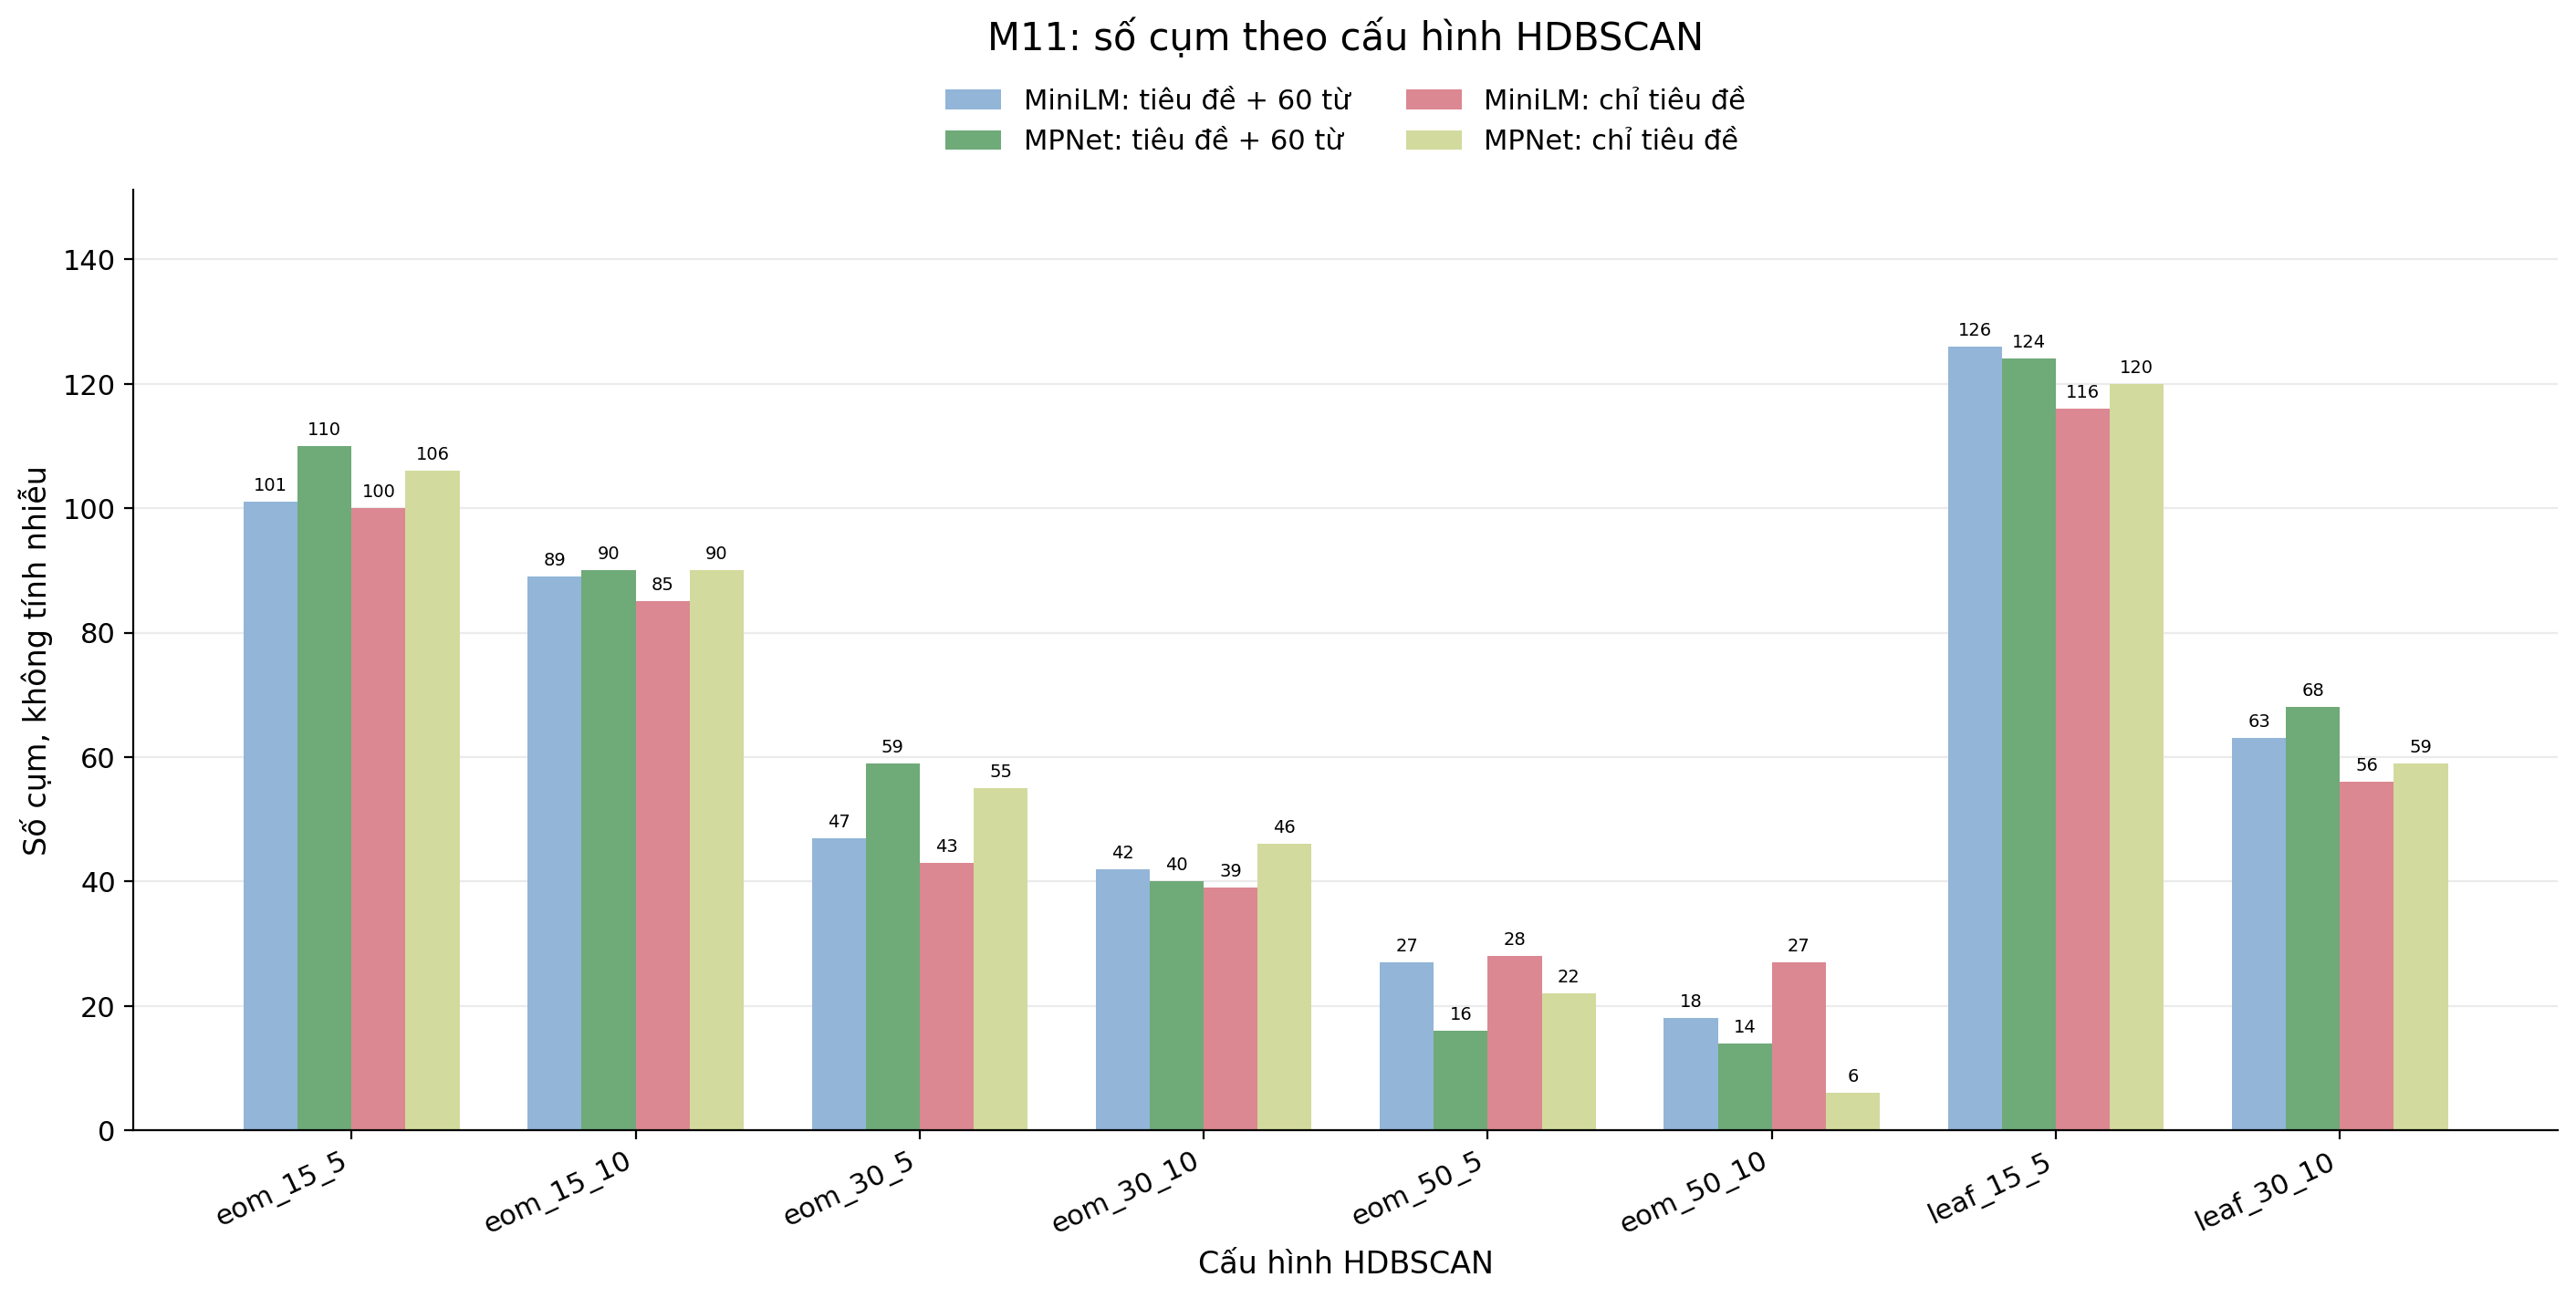

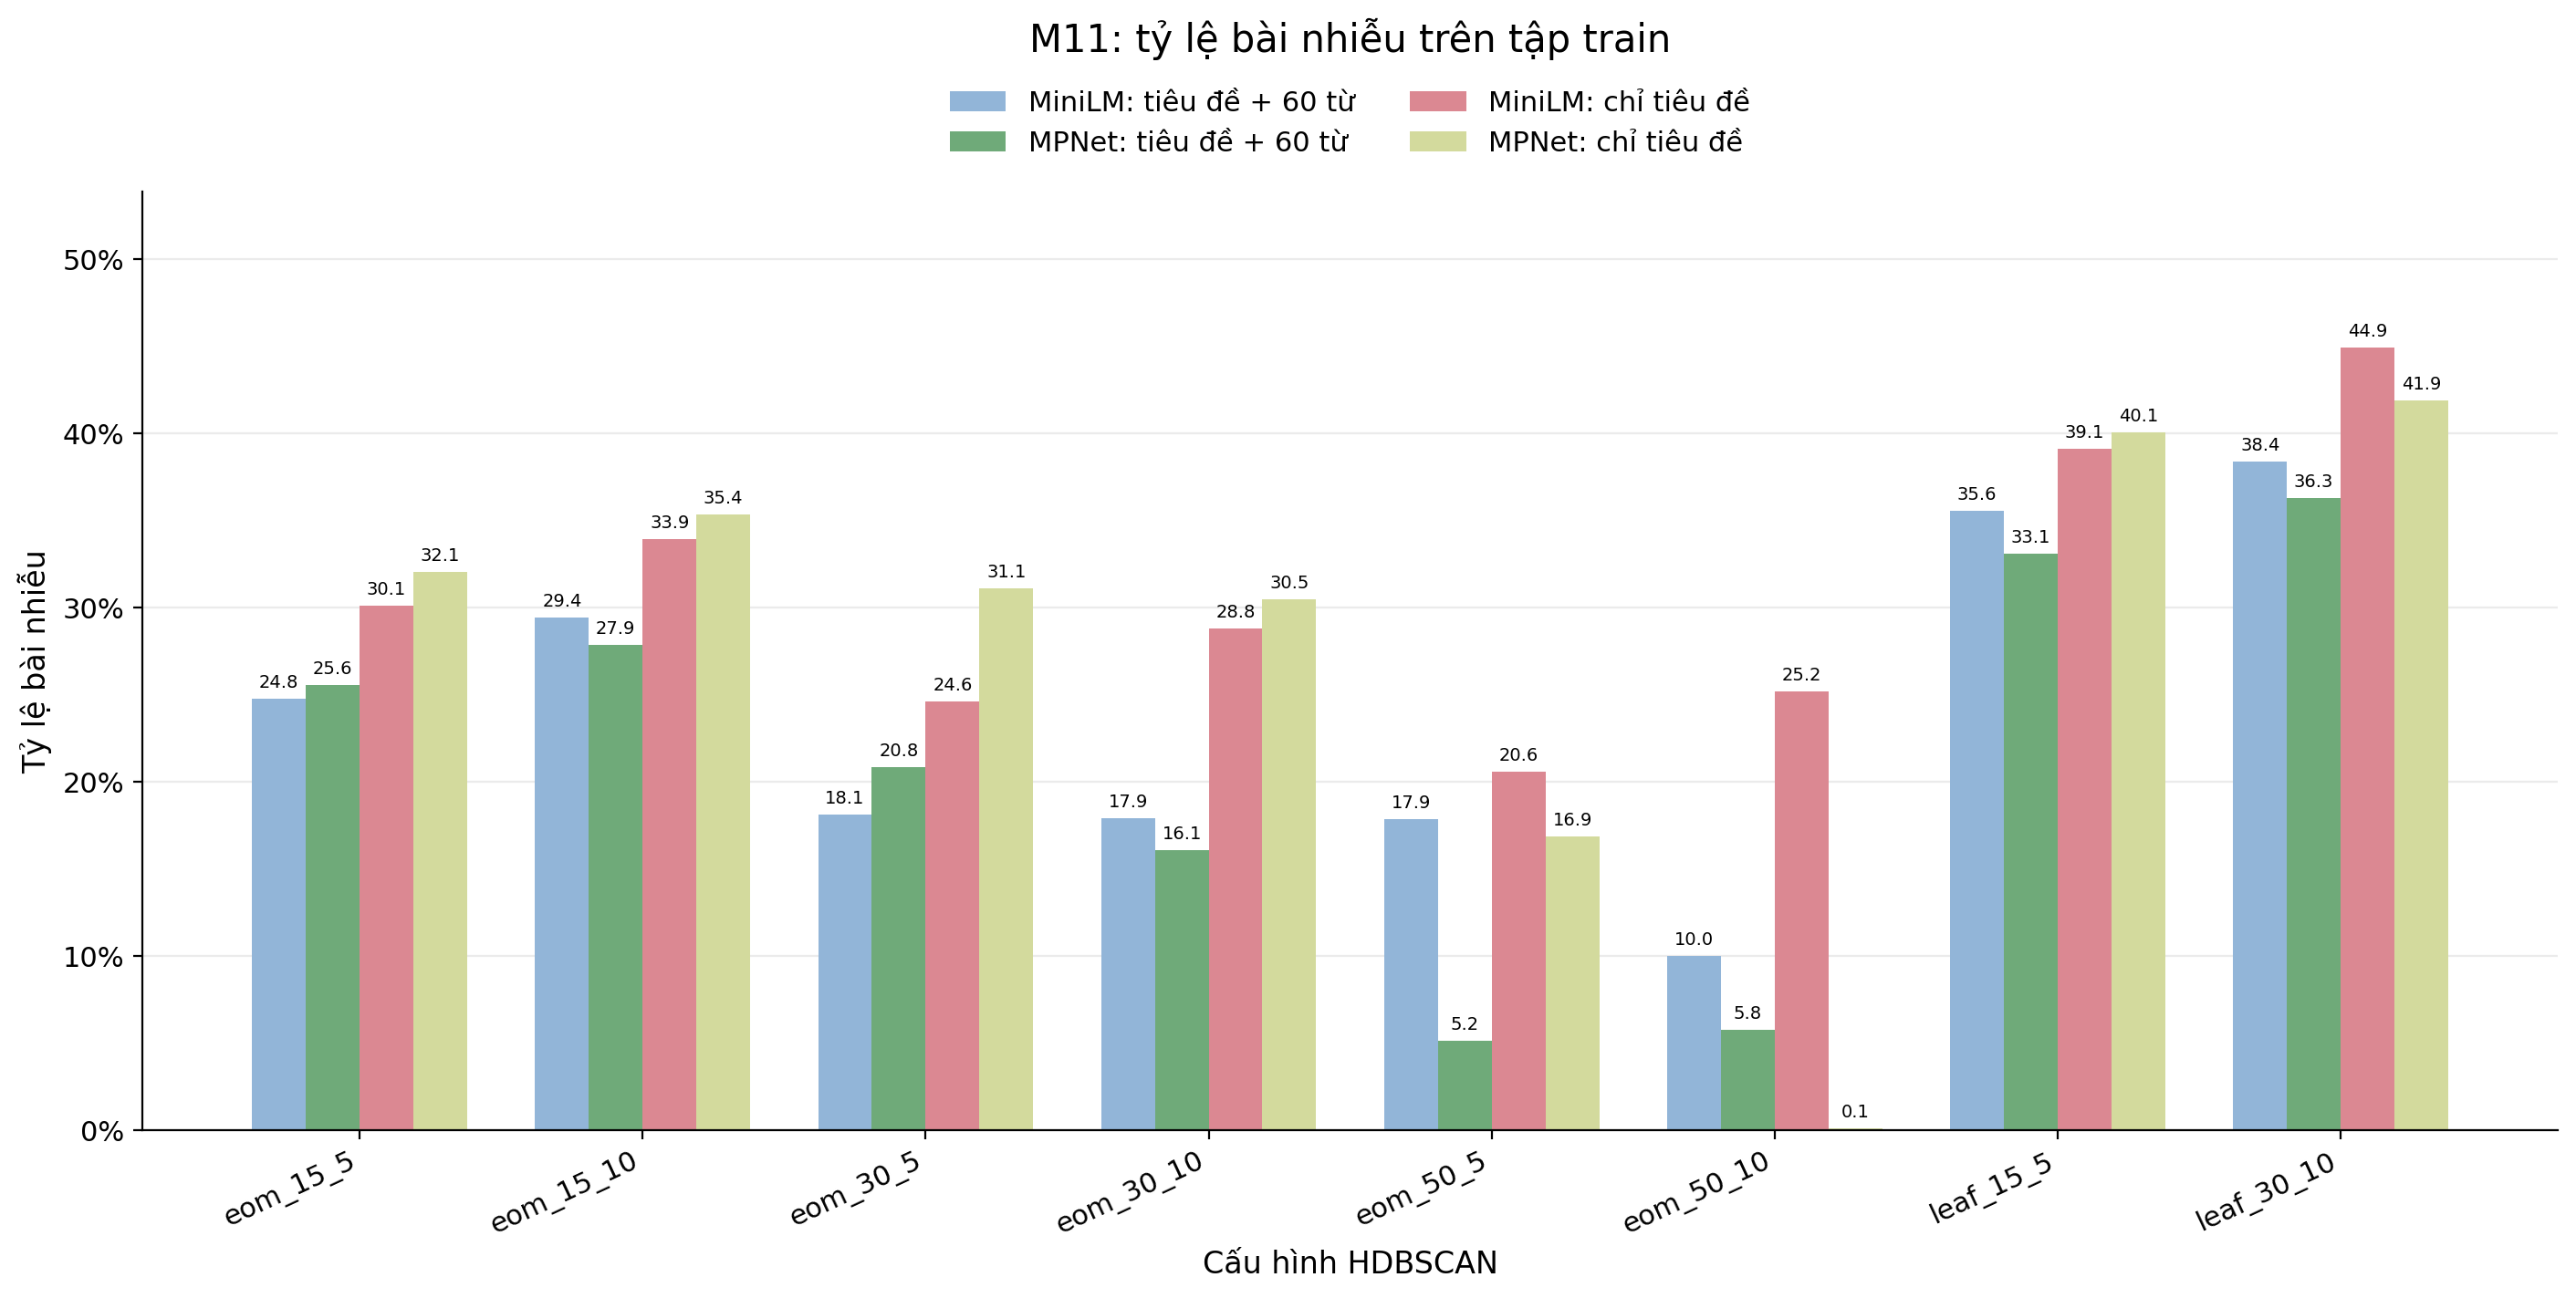

In [33]:
display(Image(filename=str(FIGURES_DIR / "m11_cluster_count.png"), width=900))
display(Image(filename=str(FIGURES_DIR / "m11_noise_ratio.png"), width=900))

### 2.2. Phân bố kích thước cụm

Mỗi hình so sánh `eom_15_5` và `leaf_15_5` trên cùng một embedding.
Nhãn `-1` không được tính là một cụm. Phạm vi trục ngang có thể khác nhau
giữa các hình, nên cần đọc giá trị trên trục khi so sánh.

MiniLM — tiêu đề + 60 từ


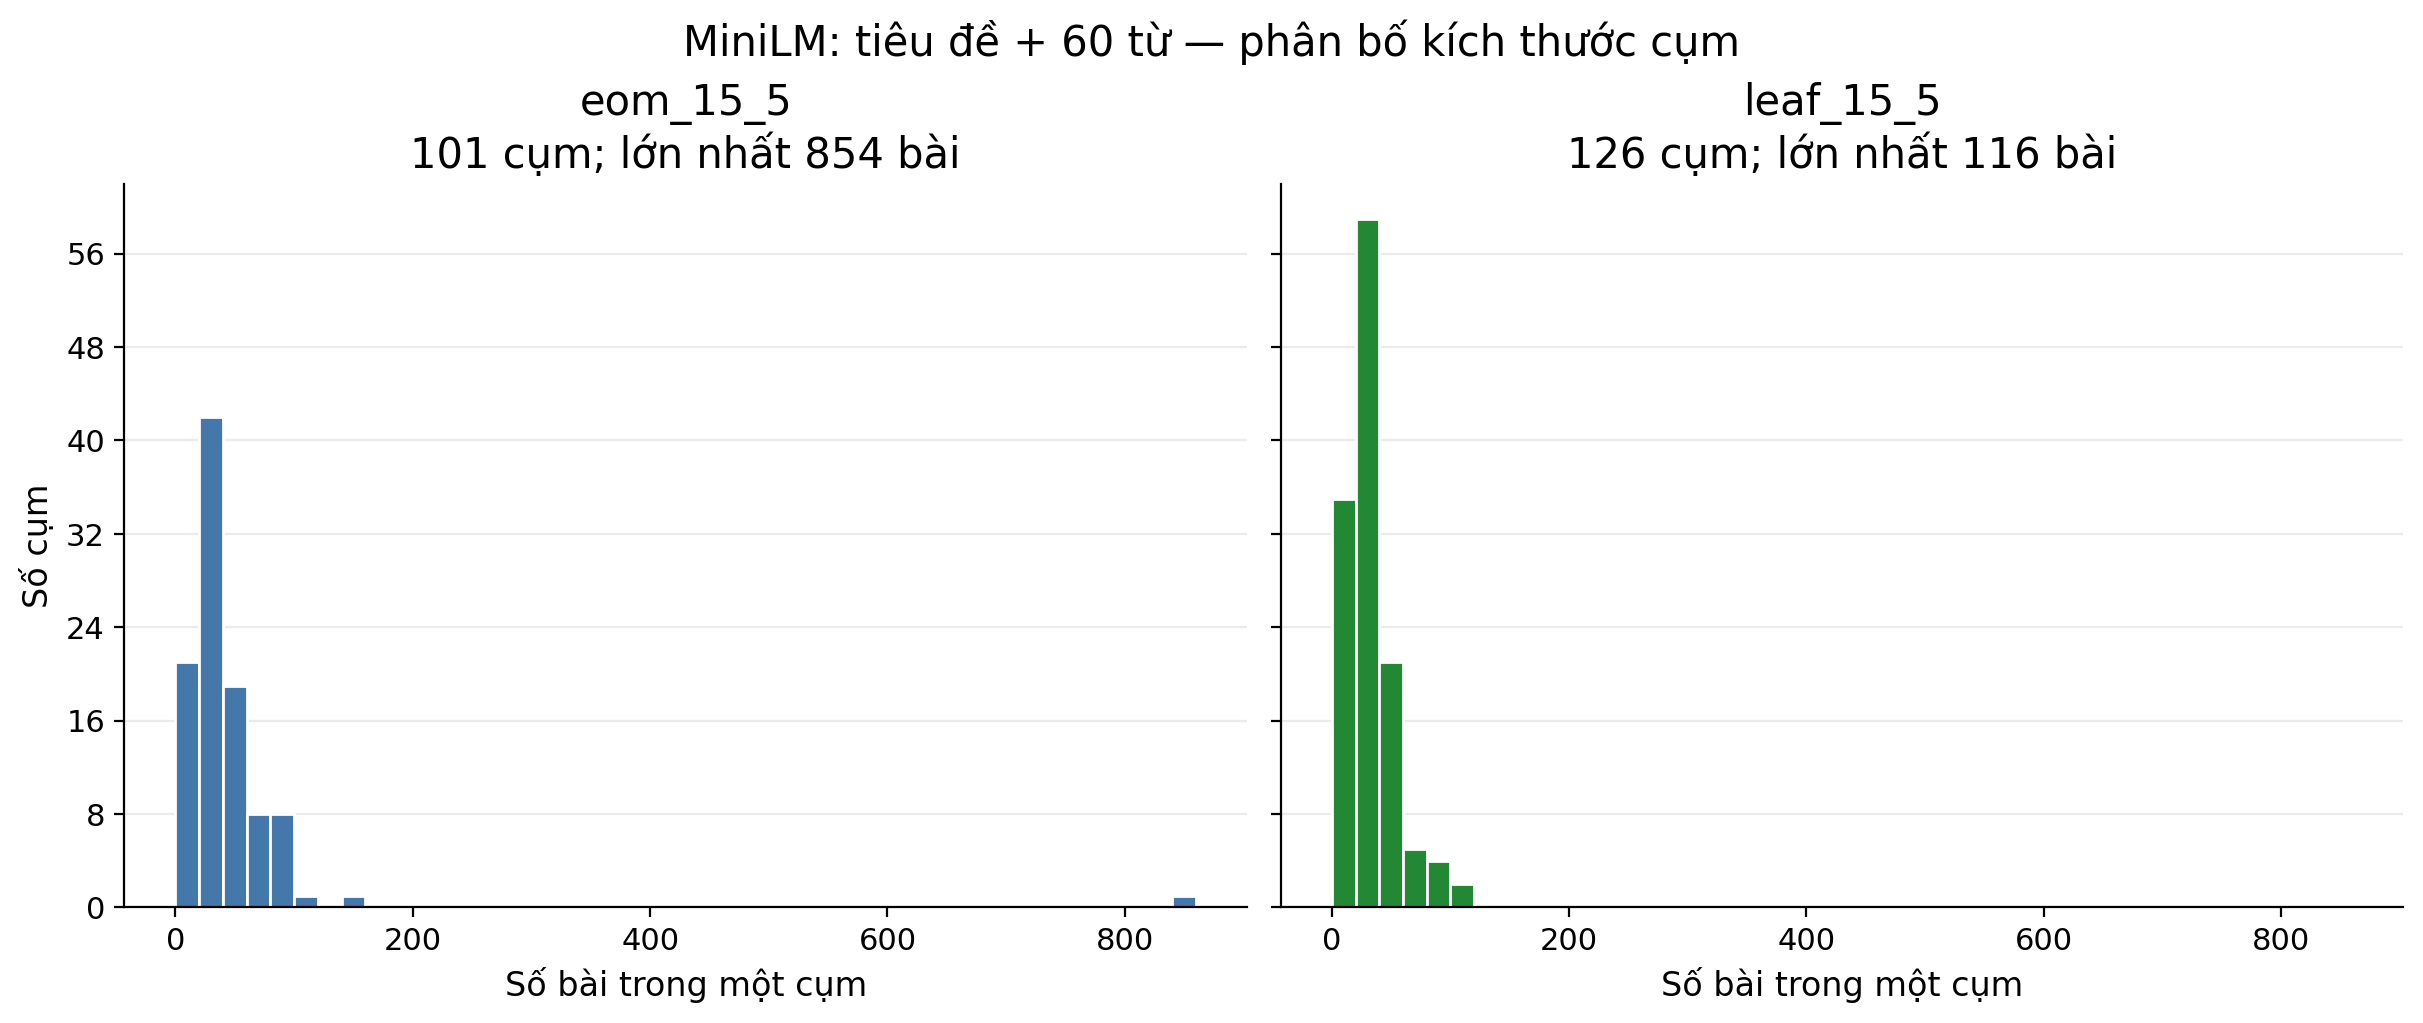

MPNet — tiêu đề + 60 từ


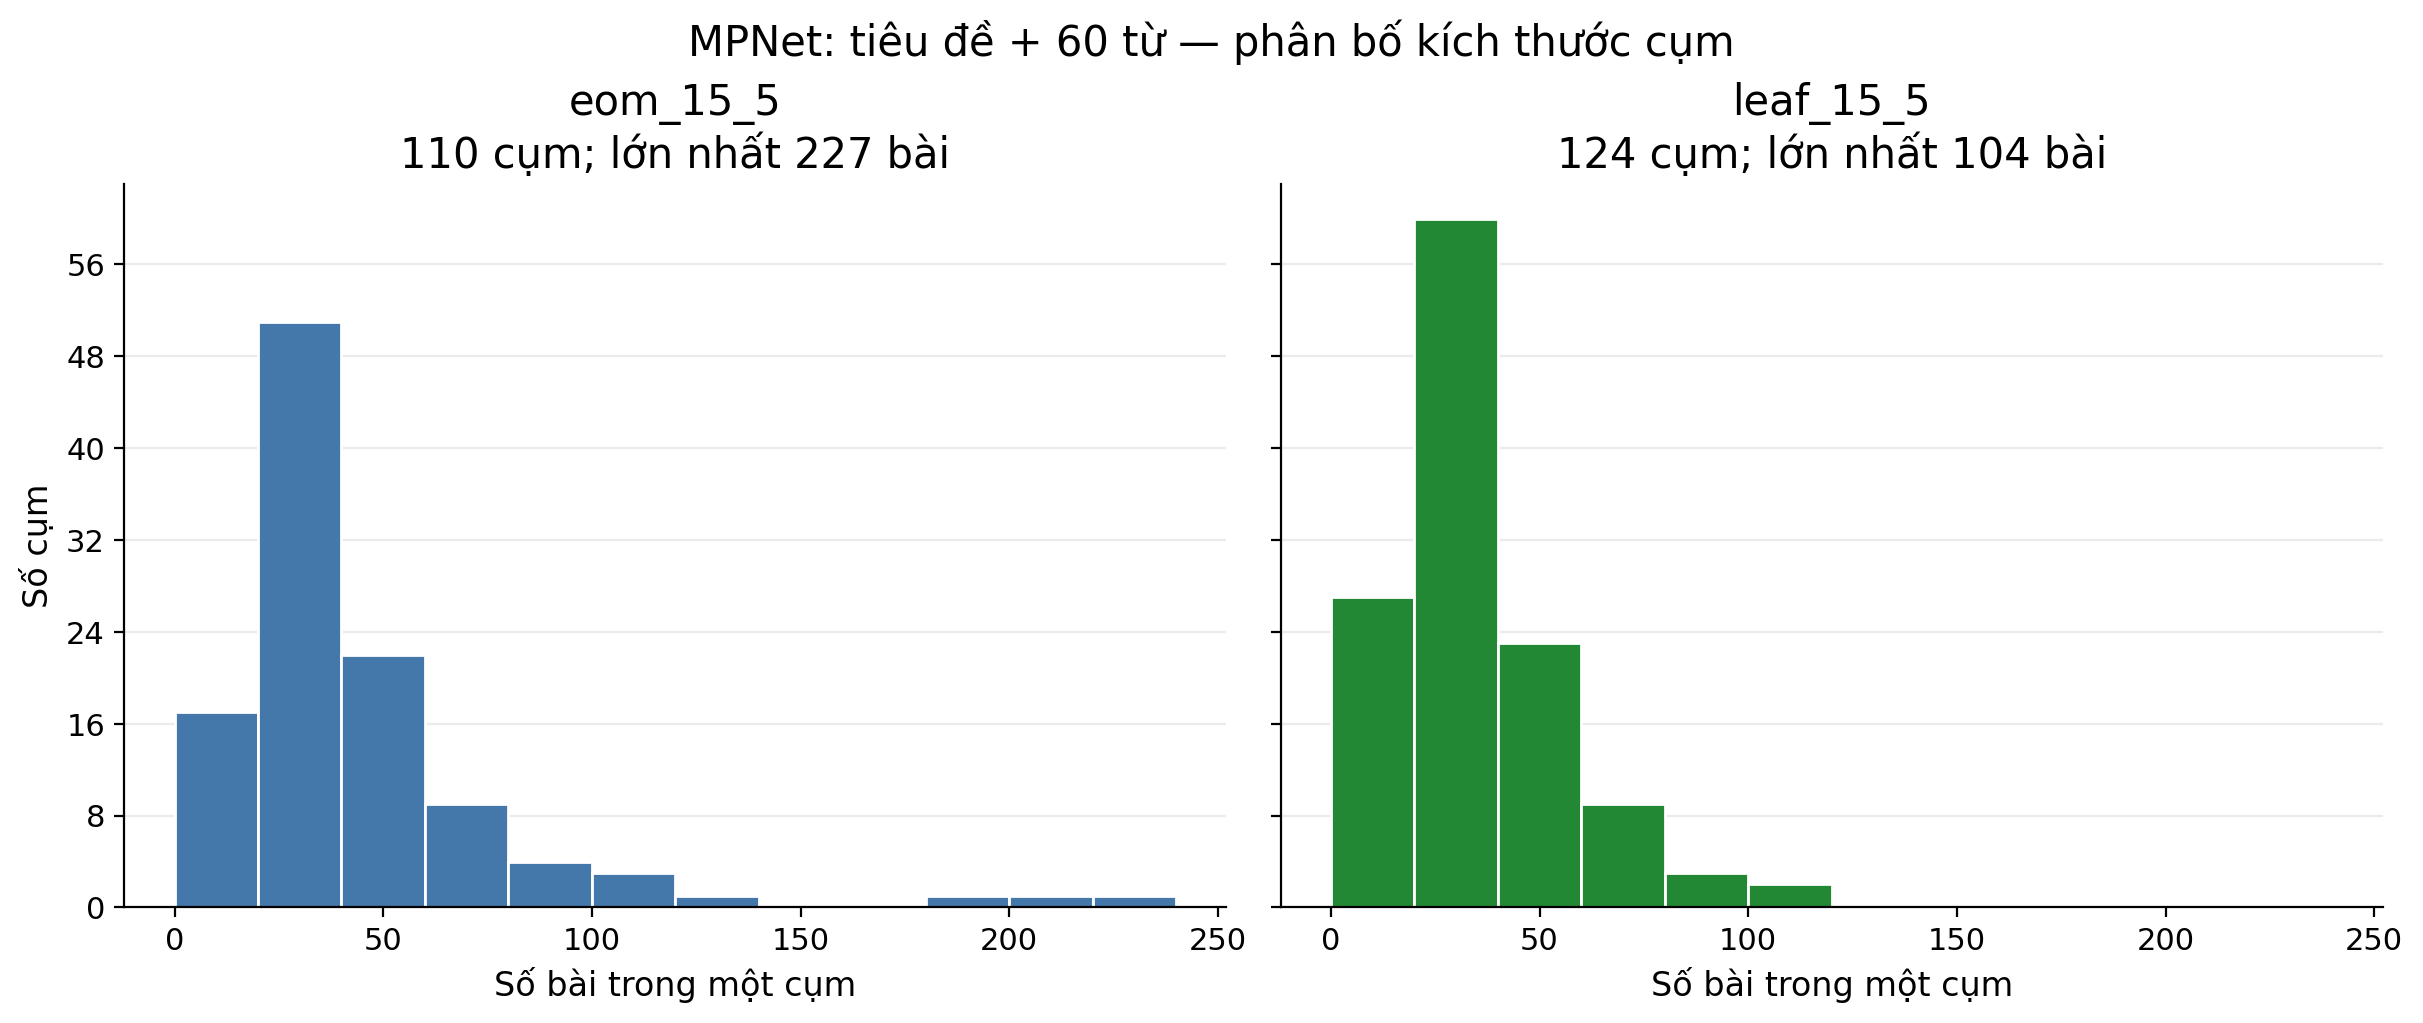

MiniLM — chỉ tiêu đề


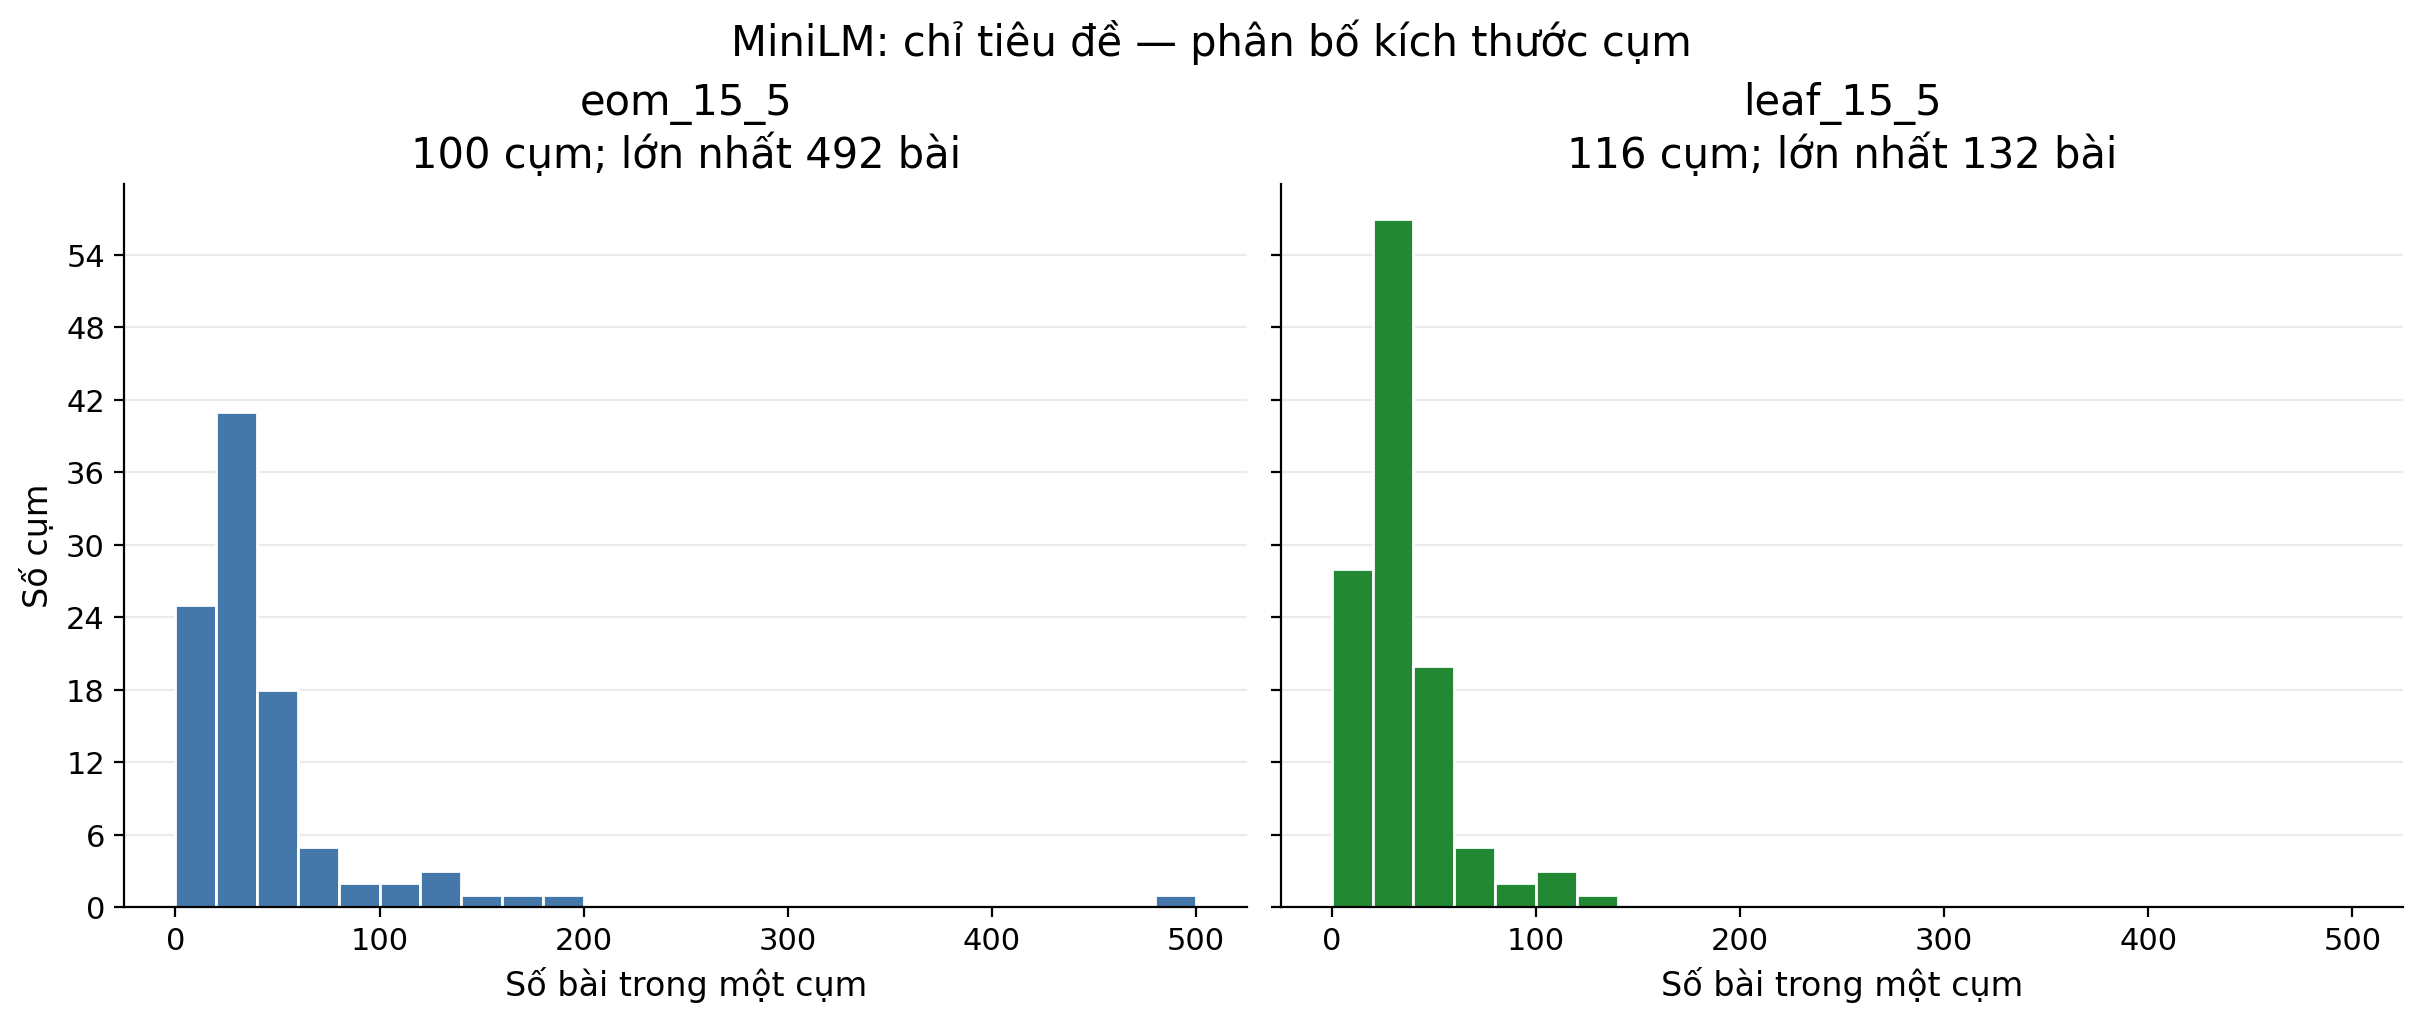

MPNet — chỉ tiêu đề


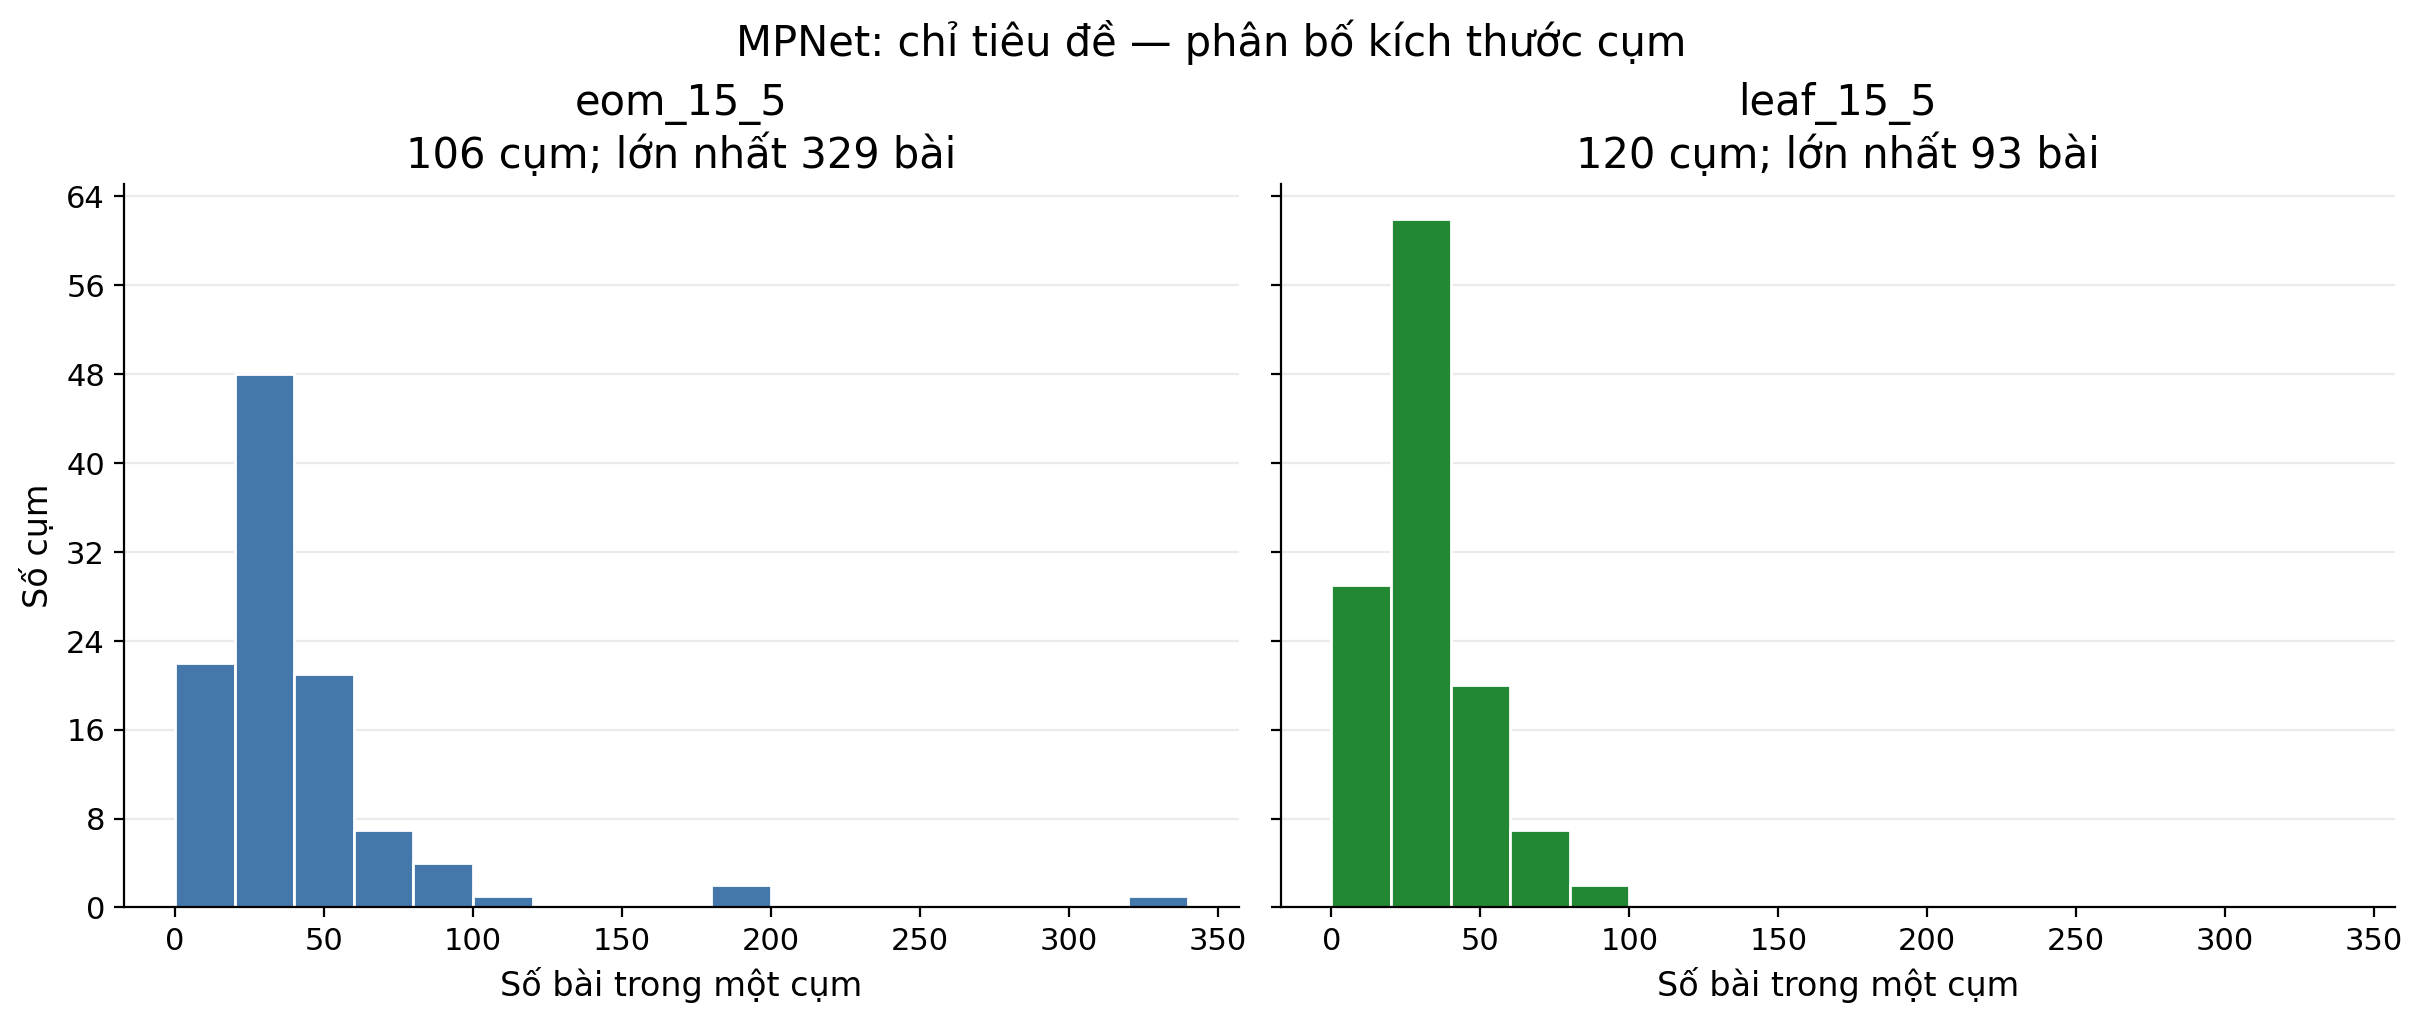

In [34]:
size_figures = {
    "MiniLM — tiêu đề + 60 từ":
        "m11_minilm_cluster_size_distribution.png",
    "MPNet — tiêu đề + 60 từ":
        "m11_cluster_size_distribution.png",
    "MiniLM — chỉ tiêu đề":
        "m11_minilm_title_only_cluster_size_distribution.png",
    "MPNet — chỉ tiêu đề":
        "m11_mpnet_title_only_cluster_size_distribution.png",
}

for description, filename in size_figures.items():
    print(description)
    display(Image(filename=str(FIGURES_DIR / filename), width=900))

### 2.3. Minh họa cụm và điểm nhiễu trên UMAP 2D

Bốn hình dùng embedding tiêu đề + 60 từ của MiniLM và MPNet.
Màu sắc thể hiện nhãn HDBSCAN M11 đã lưu. HDBSCAN được chạy trên
UMAP 5 chiều; phép chiếu 2 chiều bên dưới chỉ phục vụ trực quan hóa,
không phải ranh giới phân cụm chính xác.

MiniLM — EOM 15/5


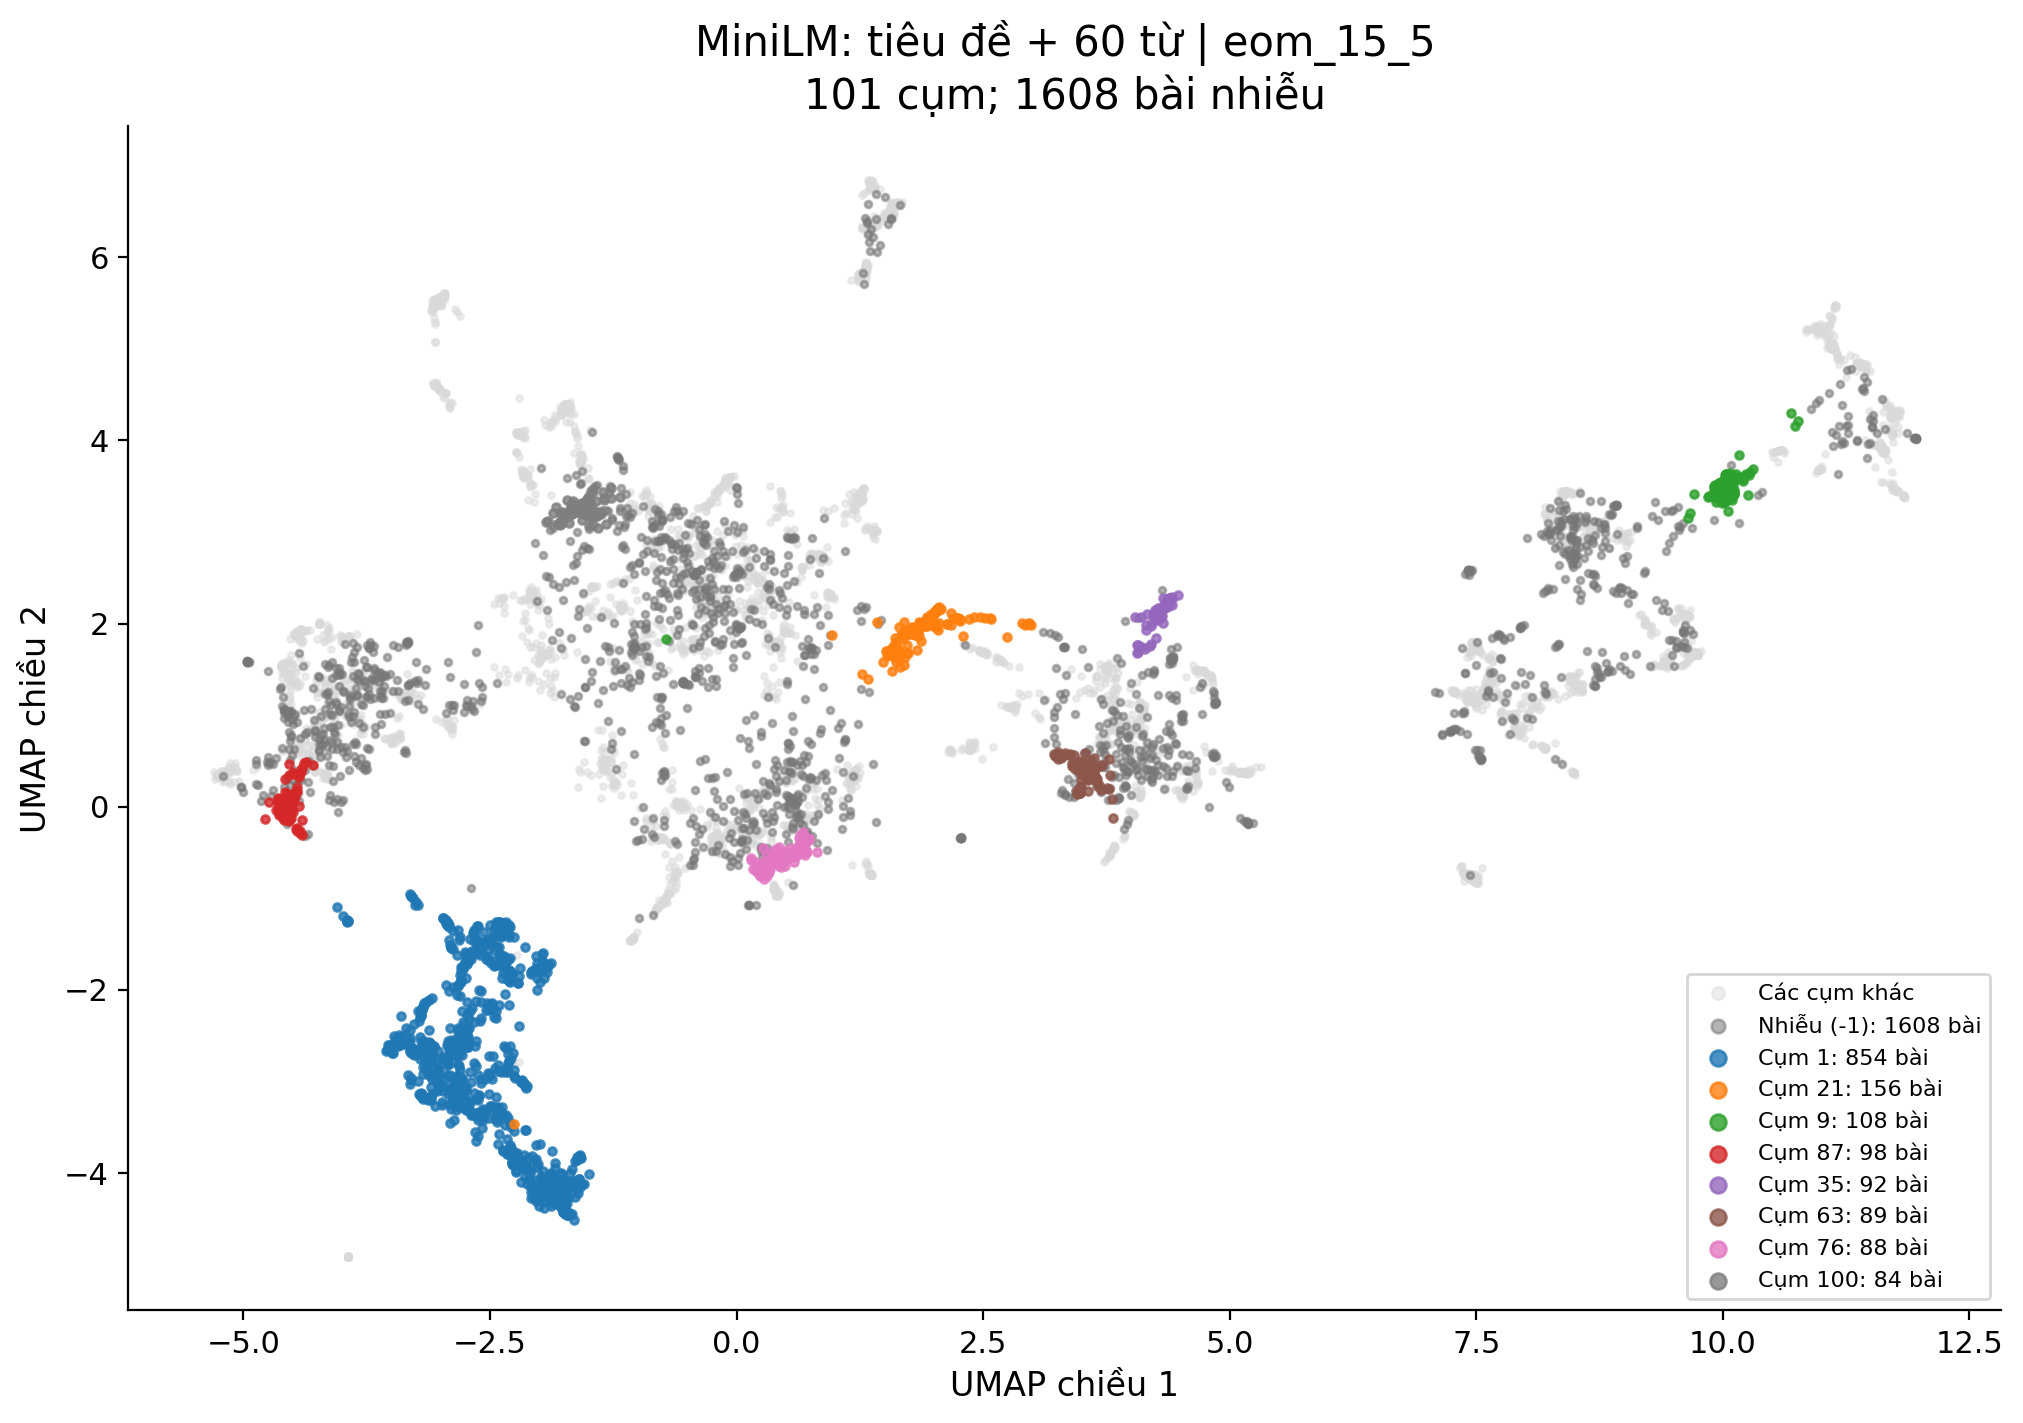

MiniLM — Leaf 15/5


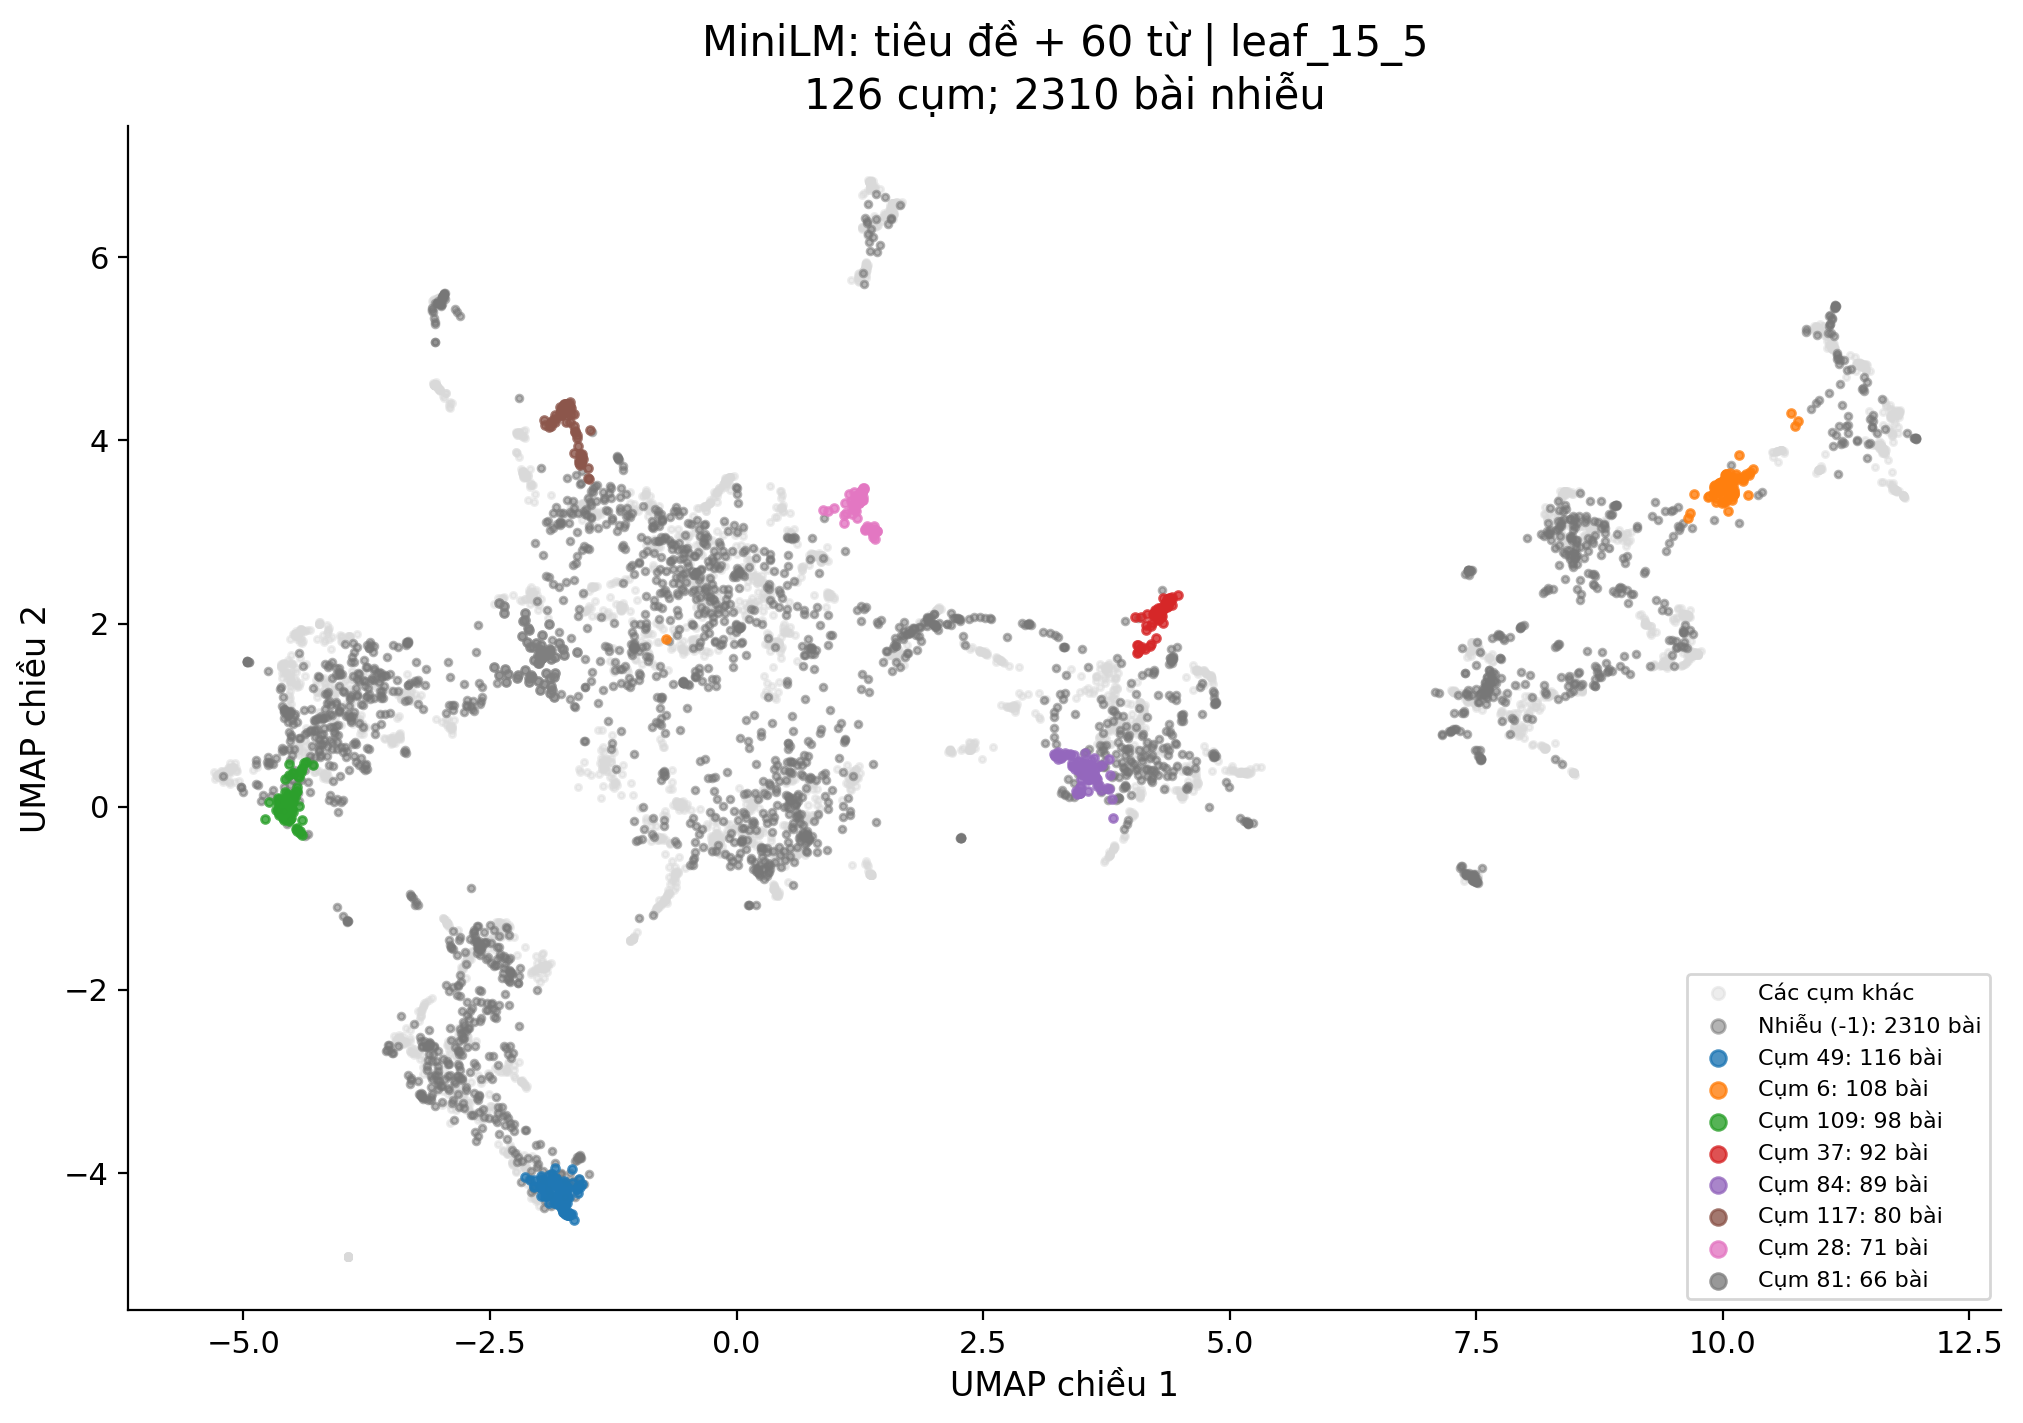

MPNet — EOM 15/5


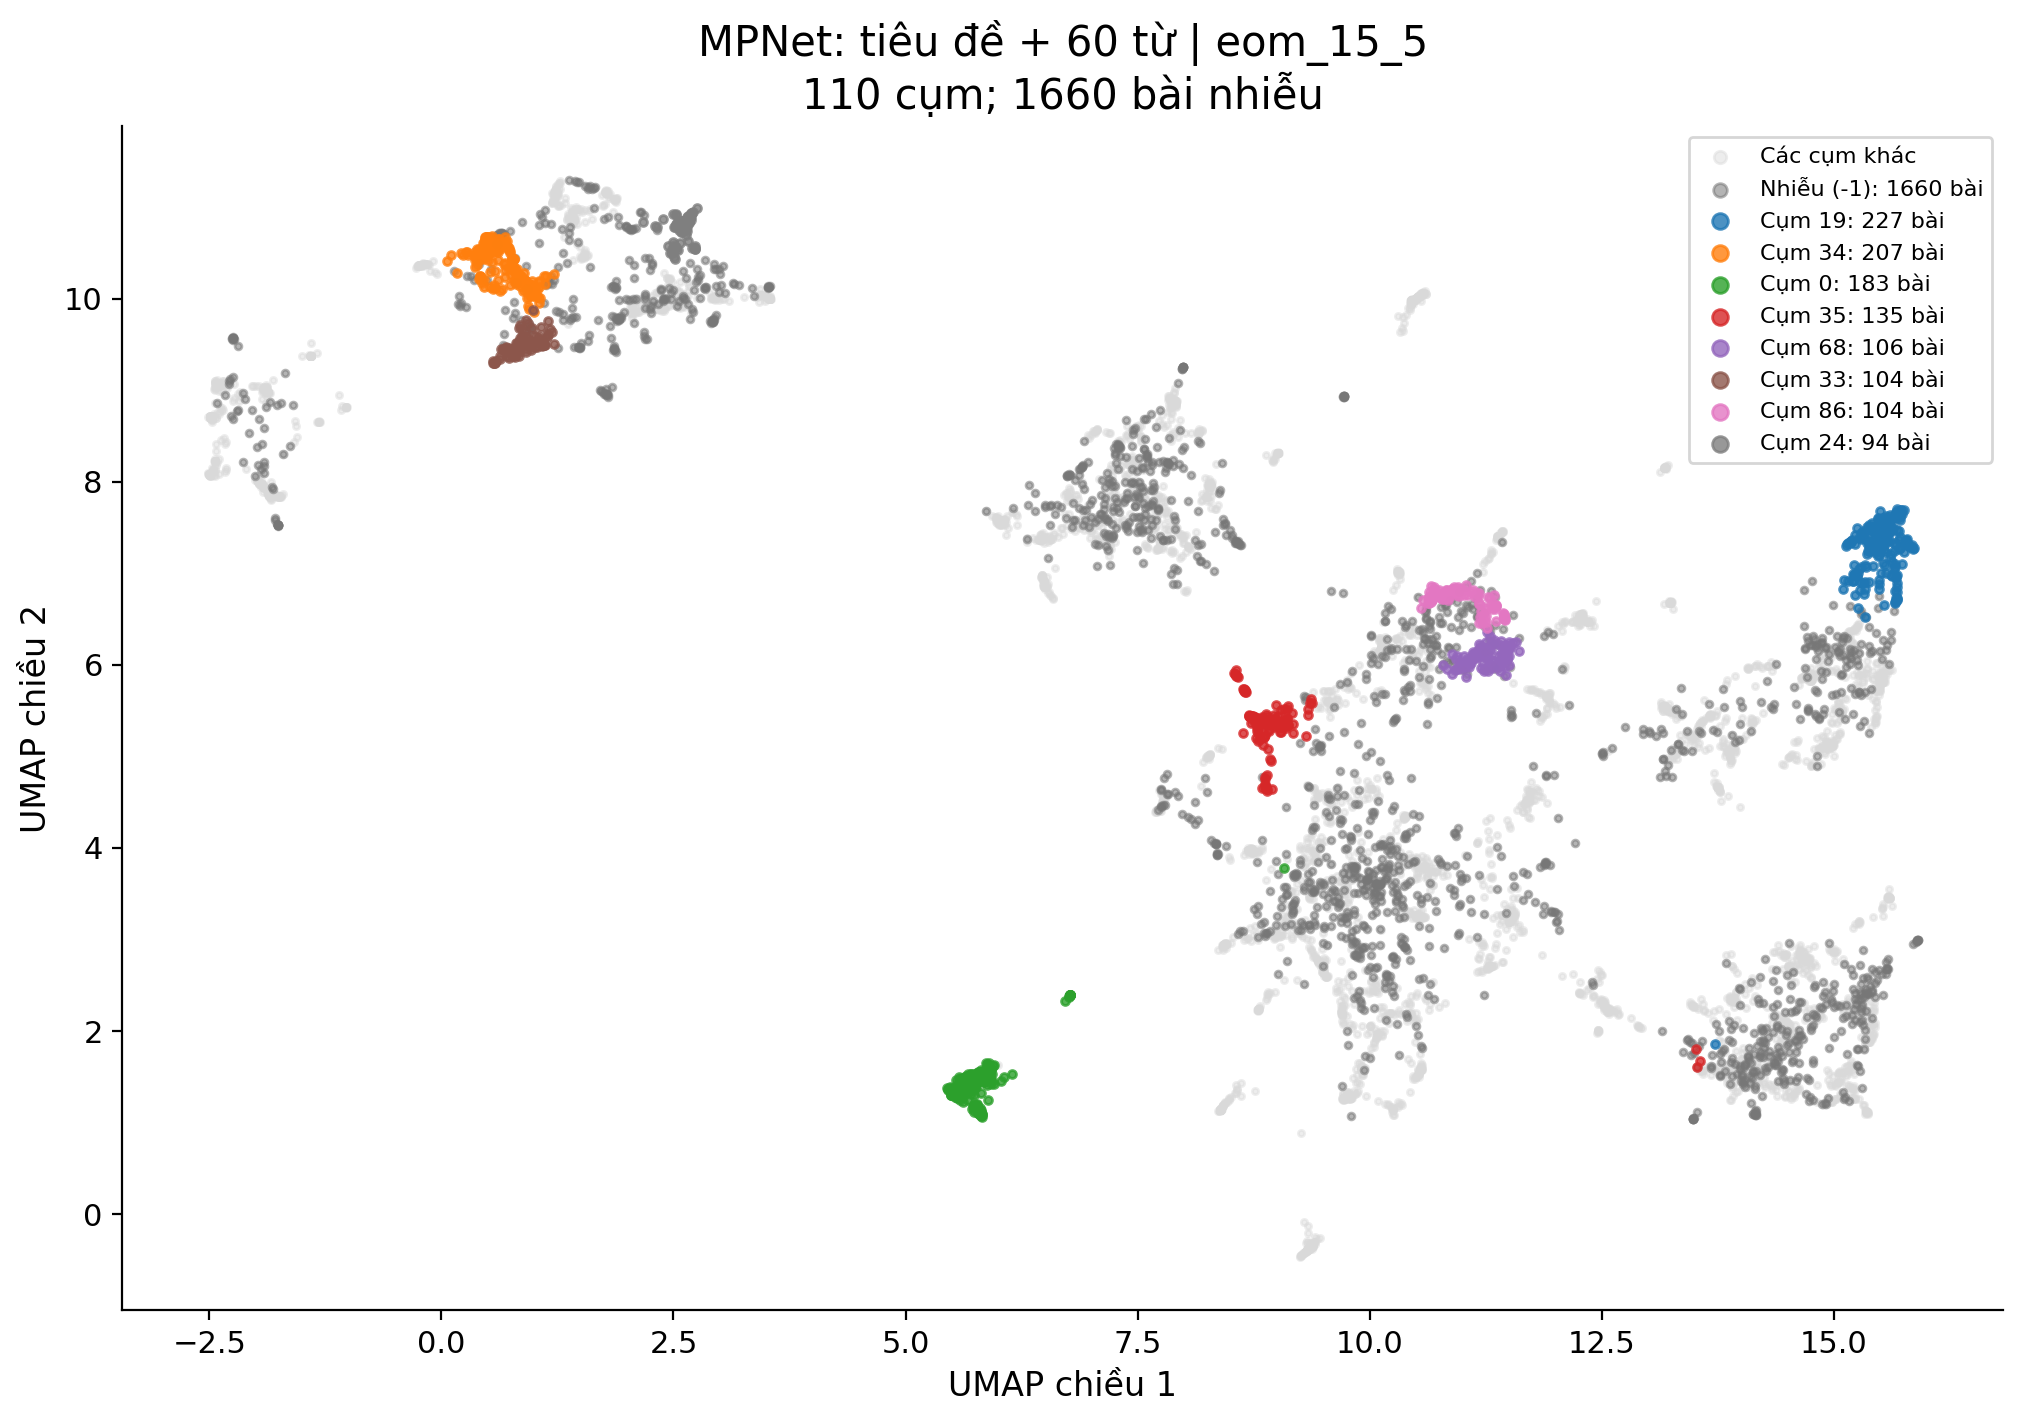

MPNet — Leaf 15/5


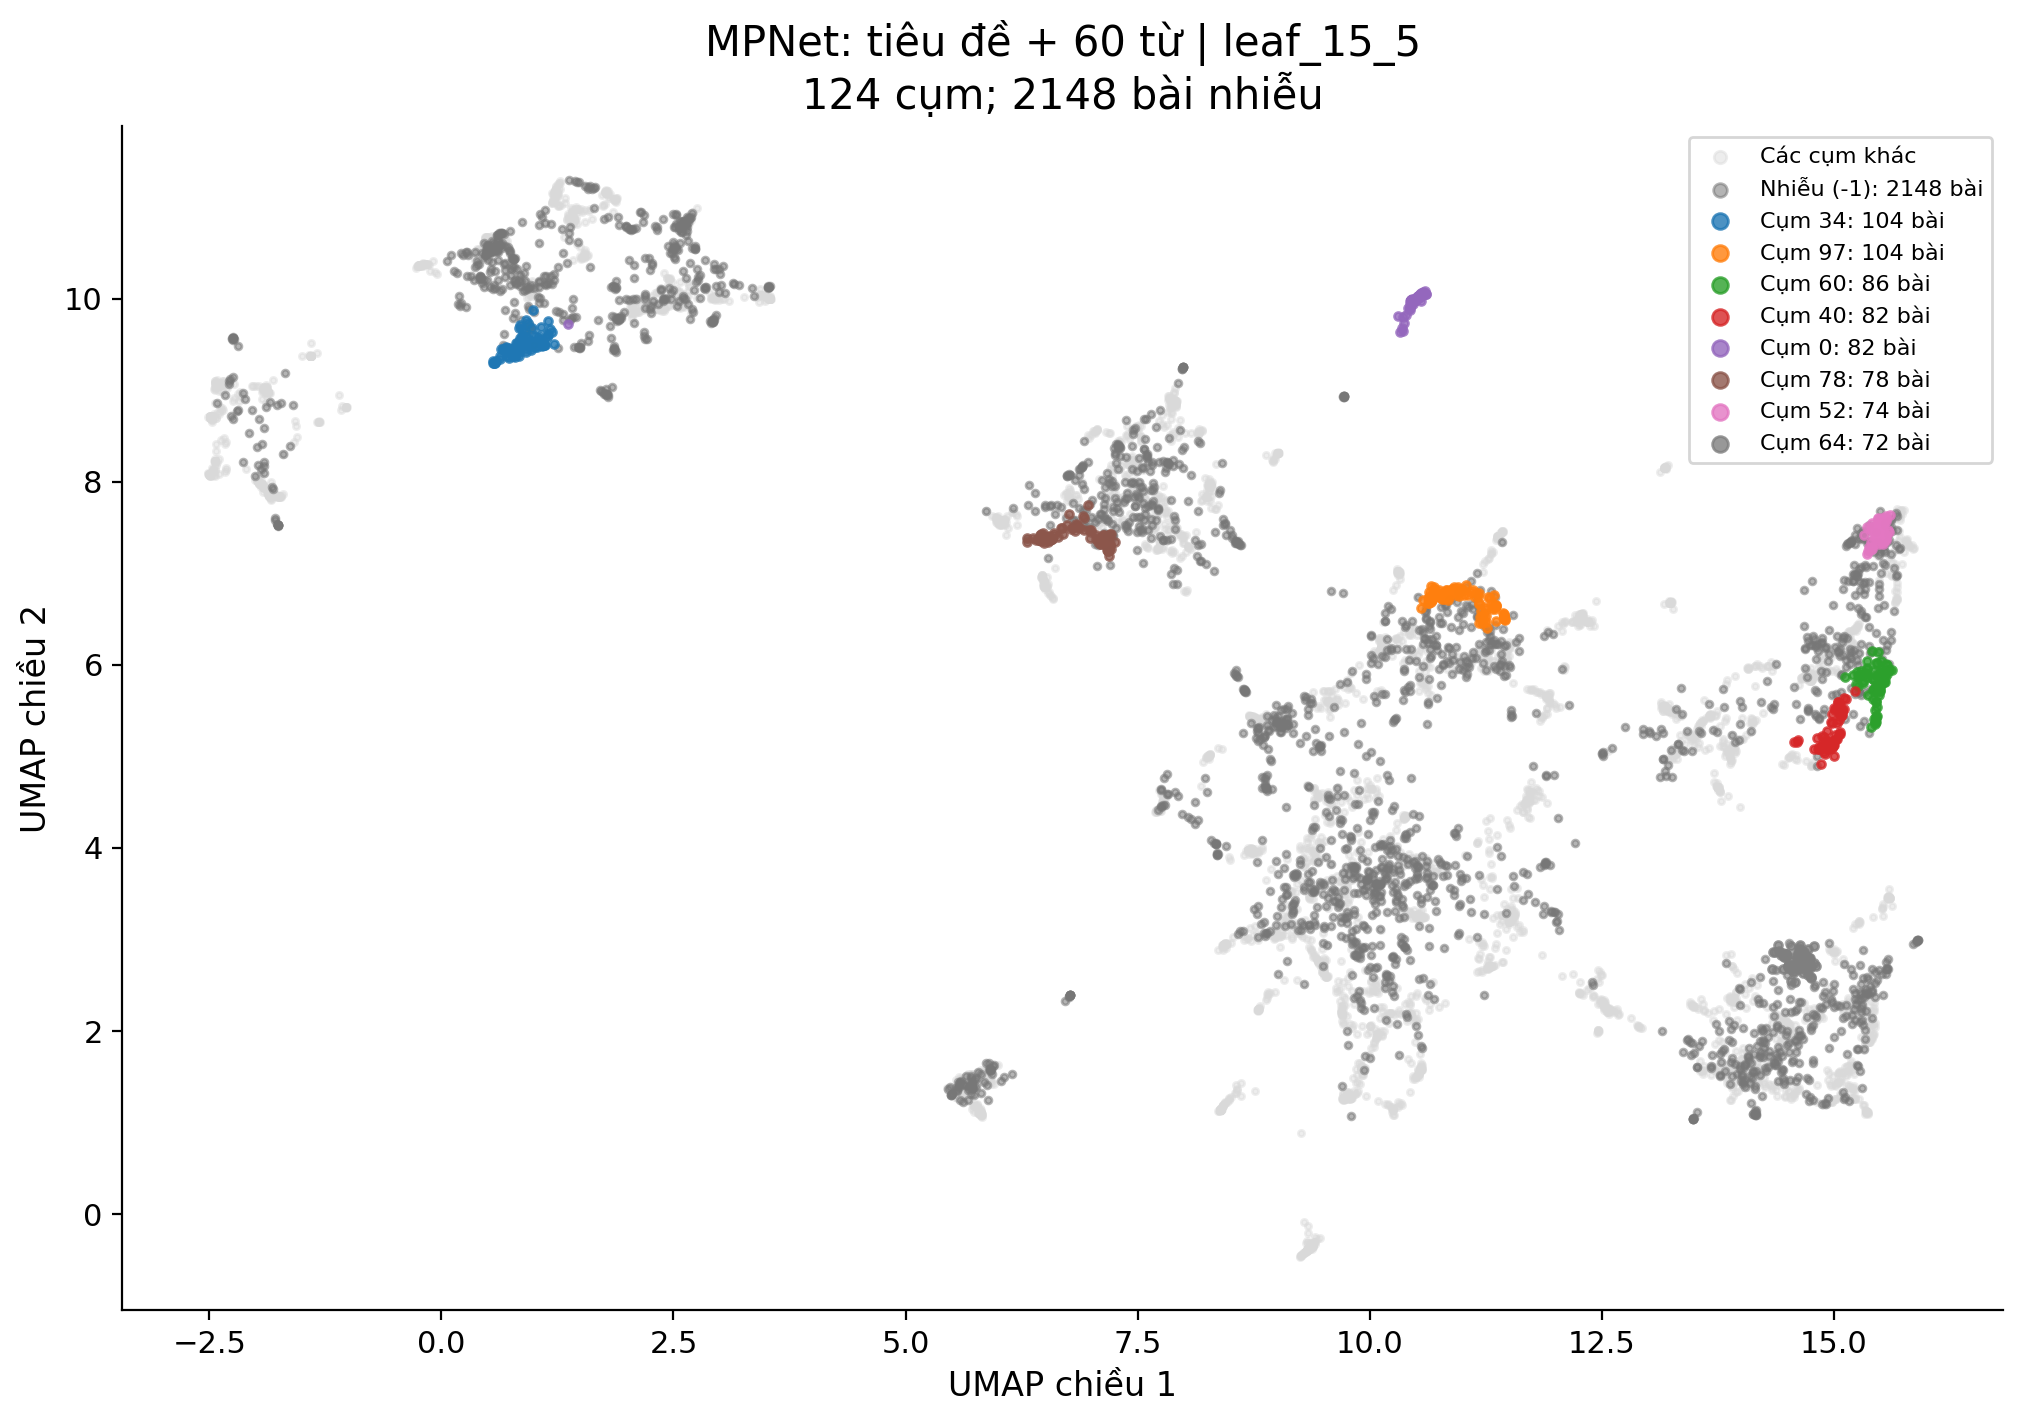

In [35]:
umap_figures = {
    "MiniLM — EOM 15/5":
        "m11_minilm_eom_15_5_umap2d.png",
    "MiniLM — Leaf 15/5":
        "m11_minilm_leaf_15_5_umap2d.png",
    "MPNet — EOM 15/5":
        "m11_mpnet_eom_15_5_umap2d.png",
    "MPNet — Leaf 15/5":
        "m11_mpnet_leaf_15_5_umap2d.png",
}

for description, filename in umap_figures.items():
    print(description)
    display(Image(filename=str(FIGURES_DIR / filename), width=850))

## 3. Phân tích outlier M12

Tỷ lệ `cluster_id == -1` được tính trên cả 32 run. Phần đọc thủ công
tập trung vào `mpnet_title_content` với `eom_15_5` và `leaf_15_5`.
Tỷ lệ theo nguồn hoặc độ dài dùng toàn bộ bài của nhóm làm mẫu số.

In [36]:
rates = pd.read_csv(
    M12_DIR / "m12_outlier_rates.csv",
    encoding="utf-8-sig",
)

review_rates = rates[
    (rates["embedding_run"] == "mpnet_title_content")
    & rates["experiment"].isin(["eom_15_5", "leaf_15_5"])
].sort_values(["experiment", "group_type", "group_value"])

display(review_rates)

,embedding_run,experiment,group_type,group_value,n_articles,n_outliers,outlier_percent
136,mpnet_title_content,eom_15_5,content_length,0-99,23,2,8.70
137,mpnet_title_content,eom_15_5,content_length,100-299,320,107,33.44
138,mpnet_title_content,eom_15_5,content_length,300-599,2390,564,23.60
139,mpnet_title_content,eom_15_5,content_length,600+,3760,987,26.25
140,mpnet_title_content,eom_15_5,overall,all,6493,1660,25.57
141,mpnet_title_content,eom_15_5,source,tuoitre,2649,680,25.67
142,mpnet_title_content,eom_15_5,source,vietnamnet,1738,434,24.97
143,mpnet_title_content,eom_15_5,source,vnexpress,2106,546,25.93
176,mpnet_title_content,leaf_15_5,content_length,0-99,23,3,13.04
177,mpnet_title_content,leaf_15_5,content_length,100-299,320,125,39.06


### Ví dụ phân loại thủ công

Các nhãn trong bảng dưới là kết quả đọc và nhận xét bài báo, không phải
nhãn do code tự dự đoán. Số lượng nhãn trong 60 dòng mẫu không đại diện
cho tỷ lệ các loại outlier của toàn bộ tập train.

In [37]:
labeled = pd.read_csv(
    M12_DIR / "m12_labeled_cases.csv",
    encoding="utf-8-sig",
)

print("Số dòng nhận xét:", len(labeled))
print("Số article_id khác nhau:", labeled["article_id"].nunique())

display(
    labeled["review_label"]
    .value_counts()
    .rename_axis("review_label")
    .reset_index(name="n_cases")
)

examples = (
    labeled.groupby("review_label", sort=True)
    .head(1)[
        [
            "experiment",
            "article_id",
            "title",
            "review_label",
            "evidence",
            "review_reason",
        ]
    ]
)
display(examples)

Số dòng nhận xét: 60
Số article_id khác nhau: 55


,review_label,n_cases
0,valid_outlier,39
1,rare_valid,16
2,data_noise,3
3,multi_topic,2


,experiment,article_id,title,review_label,evidence,review_reason
0,eom_15_5,TTR_607809186810,Lịch thi đấu Asiad ngày 28-9 của đoàn Việt Nam: chờ loạt bắn 'định đoạt' của Trịnh Thu Vinh,valid_outlier,Lịch thi đấu ASIAD ngày 28-9; ba bài gần đều về lịch thi đấu và huy chương ASIAD.,"Bài là lịch thi đấu ASIAD ngày 28/9, có nhiều lịch thi đấu tương tự ở các cụm khác nhưng bản tin này vẫn bị gán -1 t..."
1,eom_15_5,TTR_607b52b568c2,Tài xế mua 384 tuýp kem đánh răng 'hàng xách tay' về Lâm Đồng bán,rare_valid,Bài về một lô 384 tuýp kem đánh răng không chứng từ. TTR_4a04e91e98b3 về chở khí cười cũng bị -1; các bài đã vào cụm...,Giữ rare_valid tạm thời nếu xét tiểu chủ đề vận chuyển hàng không rõ nguồn gốc. Sự khác nhau giữa các vụ việc riêng ...
3,eom_15_5,VNN_14f9af2f4e8b,"Sức mua giảm mạnh, tiểu thương lớn tuổi chật vật trước bài toán chuyển đổi số",data_noise,"Trang nguồn có câu dẫn nêu sức mua ở chợ truyền thống giảm, nhưng cột content của tập dữ liệu bỏ câu dẫn và bắt đầu ...",Đầu vào văn bản thiếu câu dẫn cần để hiểu ngữ cảnh. Giữ data_noise theo nghĩa thiếu thông tin trong dữ liệu dùng cho...
13,eom_15_5,VNN_a9503ec90cf8,"Danh ca Tuấn Vũ U70 mê làm vườn ở Mỹ, MC Hoàng Oanh hút hồn ở tuổi 36",multi_topic,"Văn bản 52 từ ghép các mẩu riêng về Tuấn Vũ làm vườn, MC Hoàng Oanh và hai hoa hậu; các mẩu không cùng một sự kiện.","Nhiều tin độc lập cùng nằm trong một bản ghi, nên không có một chủ đề hẹp chung để gán cụm."


## 4. Kết luận và giới hạn

M10 đã tạo bốn bộ embedding trên cùng 6.493 bài train. M11 đã chạy
32 cấu hình kết hợp và lưu nhãn theo article_id. M12 đã tính tỷ lệ
outlier cho 32 run và nhận xét thủ công 60 dòng mẫu.

Số cụm hoặc tỷ lệ nhiễu không tự chứng minh chất lượng chủ đề. Nhãn
-1 không tự động có nghĩa bài báo lỗi. Các loại nhãn trong 60 dòng
M12 chỉ mô tả mẫu đã đọc, không đại diện cho toàn bộ outlier. Hình
UMAP 2D chỉ minh họa nhãn phân cụm được tạo trên UMAP 5 chiều.